# Sports Betting Behavioral Profiling
## Phase 2 Progress — October 27, 2026

This notebook explores simulated betting records, creates behavioral
features for each bettor, and evaluates preliminary K-means clusters.

**Research question:** Can simulated sports betting records reveal
distinct behavioral profiles, and how does observed betting performance
vary across those profiles?

This checkpoint focuses on behavioral clustering. Financial performance
comparisons will follow in the next phase.

## 1. Load the Dataset

In [1]:
import pandas as pd

df = pd.read_csv("data/bets.csv", sep=";")
display(df.head())
print("Rows and columns:", df.shape)
print("Unique bettors:", df["user_id"].nunique())

,bet_id,user_id,bet_type,sport,odds,is_win,stake,gain,GGR
0,bet_00001,3848,multiple,Ice Hockey,9.44,False,13.65,0.00,13.65
1,bet_00002,153,single,Football,8.79,False,248.45,0.00,248.45
2,bet_00003,1527,single,Football,1.50,True,3.50,5.25,-1.75
3,bet_00004,3903,single,Tennis,1.55,False,151.45,0.00,151.45
4,bet_00005,2290,single,Football,1.47,True,319.05,469.00,-149.95


Rows and columns: (100000, 9)
Unique bettors: 5000


## 2. Data Quality Checks

In [2]:
# Check column types and missing values
df.info()
display(df.isna().sum())

# Check duplicates and invalid values
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate bet IDs:", df["bet_id"].duplicated().sum())
print("Invalid stakes:", (df["stake"] <= 0).sum())
print("Invalid odds:", (df["odds"] <= 1).sum())

# Summarize numerical columns
display(df[["stake", "odds", "gain", "GGR"]].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   bet_id    100000 non-null  object 
 1   user_id   100000 non-null  int64  
 2   bet_type  100000 non-null  object 
 3   sport     100000 non-null  object 
 4   odds      100000 non-null  float64
 5   is_win    100000 non-null  bool   
 6   stake     100000 non-null  float64
 7   gain      100000 non-null  float64
 8   GGR       100000 non-null  float64
dtypes: bool(1), float64(4), int64(1), object(3)
memory usage: 6.2+ MB


bet_id      0
user_id     0
bet_type    0
sport       0
odds        0
is_win      0
stake       0
gain        0
GGR         0
dtype: int64

Duplicate rows: 0
Duplicate bet IDs: 0
Invalid stakes: 0
Invalid odds: 0


,stake,odds,gain,GGR
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,132.631652,4.700808,119.285792,13.345860
std,155.385469,4.471646,423.864572,399.962988
min,0.100000,1.100000,0.000000,-20595.230000
25%,25.050000,1.320000,0.000000,-10.822500
50%,84.900000,3.180000,0.000000,20.300000
75%,188.850000,6.440000,66.262500,115.000000
max,1000.000000,62.150000,21054.330000,999.950000


## 3. Exploratory Data Analysis

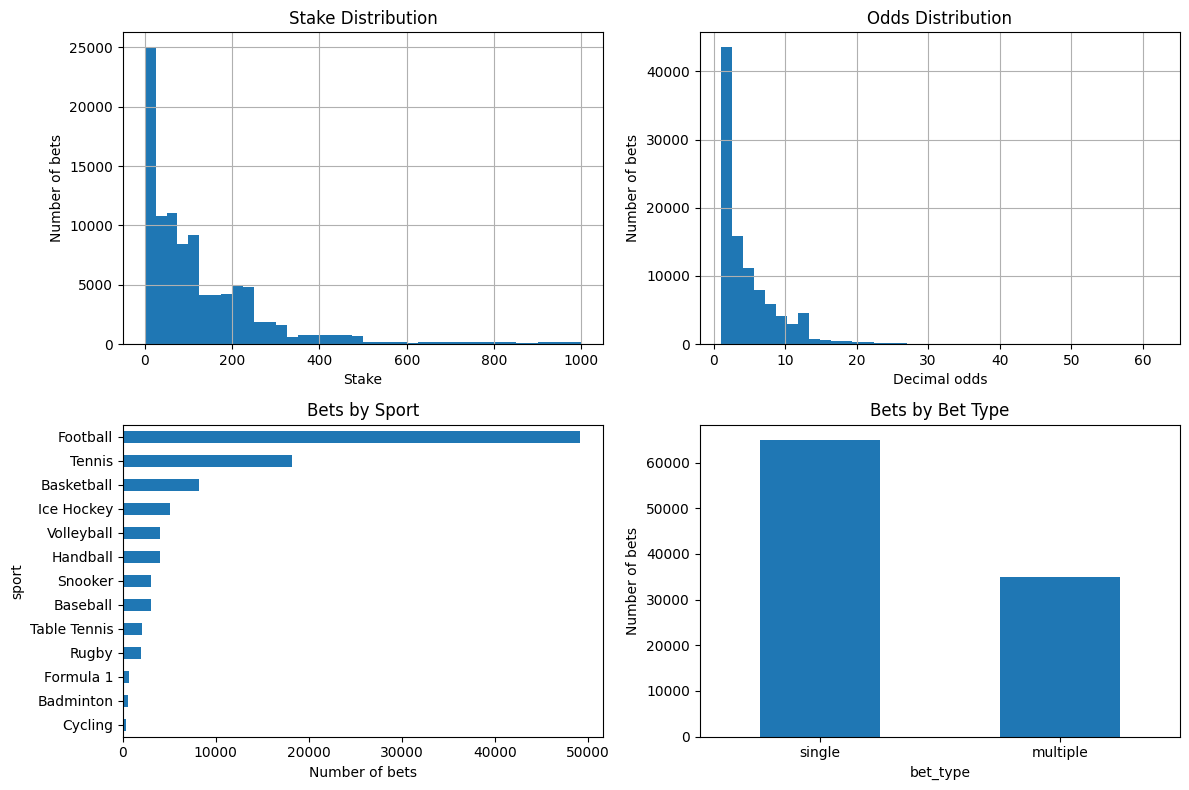

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df["stake"].hist(bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Stake Distribution")
axes[0, 0].set_xlabel("Stake")
axes[0, 0].set_ylabel("Number of bets")

df["odds"].hist(bins=40, ax=axes[0, 1])
axes[0, 1].set_title("Odds Distribution")
axes[0, 1].set_xlabel("Decimal odds")
axes[0, 1].set_ylabel("Number of bets")

df["sport"].value_counts().sort_values().plot.barh(ax=axes[1, 0])
axes[1, 0].set_title("Bets by Sport")
axes[1, 0].set_xlabel("Number of bets")

df["bet_type"].value_counts().plot.bar(
    ax=axes[1, 1], rot=0
)
axes[1, 1].set_title("Bets by Bet Type")
axes[1, 1].set_ylabel("Number of bets")

plt.tight_layout()
plt.show()

## 4. Create Bettor Features

In [4]:
# Summarize each bettor's behavior
user_features = df.groupby("user_id").agg(
    total_bets=("bet_id", "count"),
    average_stake=("stake", "mean"),
    median_stake=("stake", "median"),
    stake_std=("stake", "std"),
    average_odds=("odds", "mean"),
    odds_variance=("odds", "var"),
    sport_diversity=("sport", "nunique"),
    bet_type_diversity=("bet_type", "nunique")
)

# Calculate each bettor's proportion of bets on each sport
sport_proportions = pd.crosstab(
    df["user_id"], df["sport"], normalize="index"
).add_prefix("sport_share_")

# Calculate each bettor's proportion of each bet type
bet_type_proportions = pd.crosstab(
    df["user_id"], df["bet_type"], normalize="index"
).add_prefix("bet_type_share_")

# Combine all behavioral features
user_features = user_features.join(
    sport_proportions
).join(bet_type_proportions)

display(user_features.head())
print("Feature table shape:", user_features.shape)
print("Missing values:", user_features.isna().sum().sum())

,total_bets,average_stake,median_stake,stake_std,average_odds,odds_variance,sport_diversity,bet_type_diversity,sport_share_Badminton,sport_share_Baseball,...,sport_share_Formula 1,sport_share_Handball,sport_share_Ice Hockey,sport_share_Rugby,sport_share_Snooker,sport_share_Table Tennis,sport_share_Tennis,sport_share_Volleyball,bet_type_share_multiple,bet_type_share_single
user_id,,,,,,,,,,,,,,,,,,,,,
1,22,35.286364,34.325,19.248984,5.799091,29.988771,7,2,0.0,0.00,...,0.0,0.090909,0.136364,0.00,0.0,0.045455,0.227273,0.090909,0.272727,0.727273
2,14,5.053571,5.650,2.647819,4.447143,8.427176,5,2,0.0,0.00,...,0.0,0.071429,0.142857,0.00,0.0,0.000000,0.071429,0.071429,0.500000,0.500000
3,21,85.011905,87.100,25.532684,4.459048,12.483929,5,2,0.0,0.00,...,0.0,0.047619,0.142857,0.00,0.0,0.000000,0.238095,0.000000,0.476190,0.523810
4,10,13.915000,13.550,6.879682,5.866000,17.186249,3,2,0.0,0.00,...,0.0,0.000000,0.000000,0.00,0.0,0.000000,0.400000,0.000000,0.300000,0.700000
5,25,13.178000,14.650,6.118450,5.064400,21.560959,9,2,0.0,0.04,...,0.0,0.040000,0.040000,0.04,0.0,0.040000,0.120000,0.080000,0.320000,0.680000


Feature table shape: (5000, 23)
Missing values: 0


## 5. Inspect Features

In [5]:
print("Feature table shape:", user_features.shape)
print("Missing values:", user_features.isna().sum().sum())

# Constant features don't help distinguish bettors
constant_columns = user_features.columns[
    user_features.nunique() <= 1
].tolist()
print("Constant features:", constant_columns)

# Inspect the distributions of bettor-level features
summary = user_features.describe().T[["min", "50%", "max"]]
summary["skew"] = user_features.skew()

display(summary.round(3))

Feature table shape: (5000, 23)
Missing values: 0
Constant features: []


,min,50%,max,skew
total_bets,6.000,20.000,39.000,0.246
average_stake,3.394,81.885,815.000,2.179
median_stake,2.450,82.875,879.250,2.217
stake_std,1.883,26.630,246.352,2.241
average_odds,1.785,4.622,9.922,0.543
odds_variance,0.978,15.413,226.916,3.207
sport_diversity,2.000,6.000,12.000,0.026
bet_type_diversity,1.000,2.000,2.000,-35.323
sport_share_Badminton,0.000,0.000,0.154,3.438
sport_share_Baseball,0.000,0.000,0.286,1.416


In [6]:
# Show skewness of bettor-level numerical features
display(user_features.iloc[:, :8].skew().round(3))

# Check overlap among stake measurements
display(
    user_features[
        ["average_stake", "median_stake", "stake_std"]
    ].corr().round(3)
)

total_bets             0.246
average_stake          2.179
median_stake           2.217
stake_std              2.241
average_odds           0.543
odds_variance          3.207
sport_diversity        0.026
bet_type_diversity   -35.323
dtype: float64

,average_stake,median_stake,stake_std
average_stake,1.000,0.997,0.975
median_stake,0.997,1.000,0.969
stake_std,0.975,0.969,1.000


## 6. Prepare Clustering Inputs

In [7]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Keep the original feature table for interpretation
model_features = user_features.copy()

# Measure stake variability relative to average stake
model_features["stake_cv"] = (
    model_features["stake_std"] / model_features["average_stake"]
)

model_features = model_features.drop(columns=[
    "median_stake",
    "stake_std",
    "bet_type_share_single",
    "bet_type_diversity"
])

# Reduce skew in selected features
for column in ["average_stake", "odds_variance"]:
    model_features[column] = np.log1p(model_features[column])

# Put features on a comparable scale
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(model_features),
    index=model_features.index,
    columns=model_features.columns
)

print("Scaled feature table:", X_scaled.shape)
print("All values finite:", np.isfinite(X_scaled.to_numpy()).all())
display(X_scaled.head())

Scaled feature table: (5000, 20)
All values finite: True


,total_bets,average_stake,average_odds,odds_variance,sport_diversity,sport_share_Badminton,sport_share_Baseball,sport_share_Basketball,sport_share_Cycling,sport_share_Football,sport_share_Formula 1,sport_share_Handball,sport_share_Ice Hockey,sport_share_Rugby,sport_share_Snooker,sport_share_Table Tennis,sport_share_Tennis,sport_share_Volleyball,bet_type_share_multiple,stake_cv
user_id,,,,,,,,,,,,,,,,,,,,
1,0.448070,-0.556256,1.059350,0.969952,0.446403,-0.312854,-0.764177,0.888917,-0.240684,-1.903971,-0.353377,1.141786,1.699127,-0.611041,-0.76915,0.792121,0.522087,1.131768,-0.708470,1.294217
2,-1.344211,-2.006833,-0.243452,-1.004035,-0.920835,-0.312854,-0.764177,-1.310609,-0.240684,1.303169,-0.353377,0.707495,1.827384,-0.611041,-0.76915,-0.614295,-1.245234,0.698161,1.387195,1.117104
3,0.224035,0.142826,-0.231980,-0.410357,-0.920835,-0.312854,-0.764177,0.993657,-0.240684,-0.553596,-0.353377,0.176695,1.827384,-0.611041,-0.76915,-0.614295,0.644817,-0.891730,1.167649,-0.720014
4,-2.240351,-1.276424,1.123827,0.085894,-2.288074,-0.312854,-0.764177,0.302377,-0.240684,0.065326,-0.353377,-0.884905,-0.994271,-0.611041,-0.76915,-0.614295,2.480867,-0.891730,-0.456990,0.874389
5,1.120176,-1.317472,0.351366,0.443451,1.813642,-0.312854,0.257557,0.624974,-0.240684,-0.107973,-0.353377,0.006839,-0.204208,0.649625,-0.76915,0.623351,-0.694419,0.888948,-0.272572,0.626971


## 7. Compare K-Means Models

,k,inertia,silhouette,smallest_cluster
0,2,92874.9979,0.0829,1871
1,3,88194.6862,0.0619,1536
2,4,84166.1125,0.0688,296
3,5,80858.6005,0.0640,294
4,6,77764.6010,0.0657,293
5,7,76296.0366,0.0614,291
6,8,73492.1913,0.0625,290


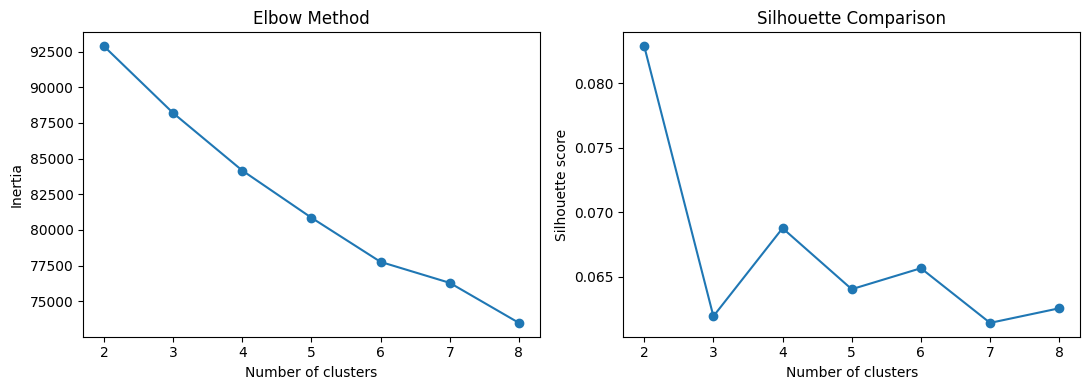

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
models = {}

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    models[k] = model

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": score,
        "smallest_cluster": pd.Series(labels).value_counts().min()
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(results_df["k"], results_df["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(results_df["k"], results_df["silhouette"], marker="o")
axes[1].set_title("Silhouette Comparison")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

## 8. Preliminary Cluster Profiles

In [9]:
# Use the fitted two-cluster model
chosen_k = 2
clustered_users = user_features.copy()
clustered_users["cluster"] = models[chosen_k].labels_

# Include relative stake variability for interpretation
clustered_users["stake_cv"] = (
    clustered_users["stake_std"] /
    clustered_users["average_stake"]
)

print("Bettors per cluster:")
display(clustered_users["cluster"].value_counts().sort_index())

# Summarize behavior in original units
profile_columns = [
    "total_bets",
    "average_stake",
    "stake_cv",
    "average_odds",
    "odds_variance",
    "sport_diversity",
    "bet_type_share_multiple"
]

display(
    clustered_users.groupby("cluster")[profile_columns]
    .mean()
    .round(3)
)

# Compare sport preferences
sport_columns = [
    column for column in user_features.columns
    if column.startswith("sport_share_")
]

display(
    clustered_users.groupby("cluster")[sport_columns]
    .mean()
    .round(3)
)

Bettors per cluster:


cluster
0    3129
1    1871
Name: count, dtype: int64

,total_bets,average_stake,stake_cv,average_odds,odds_variance,sport_diversity,bet_type_share_multiple
cluster,,,,,,,
0,20.051,197.094,0.308,4.693,19.922,6.351,0.348
1,19.914,23.149,0.522,4.711,20.078,6.340,0.352


,sport_share_Badminton,sport_share_Baseball,sport_share_Basketball,sport_share_Cycling,sport_share_Football,sport_share_Formula 1,sport_share_Handball,sport_share_Ice Hockey,sport_share_Rugby,sport_share_Snooker,sport_share_Table Tennis,sport_share_Tennis,sport_share_Volleyball
cluster,,,,,,,,,,,,,
0,0.005,0.03,0.081,0.003,0.493,0.007,0.04,0.048,0.020,0.031,0.02,0.182,0.041
1,0.006,0.03,0.082,0.003,0.491,0.007,0.04,0.054,0.019,0.030,0.02,0.181,0.039


## 9. Check and Refine Stability

In [10]:
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# Repeat two-cluster K-means with different starting seeds
seed_labels = {}

for seed in [0, 1, 2, 3, 42]:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    )
    seed_labels[seed] = model.fit_predict(X_scaled)

# Compare every pair of runs
stability_results = []

for seed_a, seed_b in combinations(seed_labels, 2):
    stability_results.append({
        "seed_a": seed_a,
        "seed_b": seed_b,
        "ARI": adjusted_rand_score(
            seed_labels[seed_a],
            seed_labels[seed_b]
        )
    })

stability_df = pd.DataFrame(stability_results)
display(stability_df.round(3))
print("Mean ARI:", round(stability_df["ARI"].mean(), 3))

,seed_a,seed_b,ARI
0,0,1,0.011
1,0,2,0.011
2,0,3,0.011
3,0,42,0.011
4,1,2,0.999
5,1,3,0.999
6,1,42,0.999
7,2,3,0.998
8,2,42,0.998
9,3,42,1.000


Mean ARI: 0.604


In [11]:
# Check whether more starting attempts improve consistency
refined_labels = {}
refined_results = []

for seed in [0, 1, 2, 3, 42]:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=50
    )

    refined_labels[seed] = model.fit_predict(X_scaled)

    refined_results.append({
        "seed": seed,
        "inertia": model.inertia_
    })

display(pd.DataFrame(refined_results).round(3))

pairwise_results = []

for seed_a, seed_b in combinations(refined_labels, 2):
    pairwise_results.append({
        "seed_a": seed_a,
        "seed_b": seed_b,
        "ARI": adjusted_rand_score(
            refined_labels[seed_a],
            refined_labels[seed_b]
        )
    })

refined_stability_df = pd.DataFrame(pairwise_results)
display(refined_stability_df.round(3))

,seed,inertia
0,0,92875.013
1,1,92874.984
2,2,92874.983
3,3,92874.998
4,42,92874.998


,seed_a,seed_b,ARI
0,0,1,0.998
1,0,2,0.998
2,0,3,0.997
3,0,42,0.997
4,1,2,0.999
5,1,3,0.999
6,1,42,0.999
7,2,3,0.998
8,2,42,0.998
9,3,42,1.000


## 10. Visualize Refined Clusters

cluster
0    3129
1    1871
Name: count, dtype: int64

,total_bets,average_stake,stake_cv,average_odds,odds_variance,sport_diversity,bet_type_share_multiple
cluster,,,,,,,
0,20.051,197.094,0.308,4.693,19.922,6.351,0.348
1,19.914,23.149,0.522,4.711,20.078,6.340,0.352


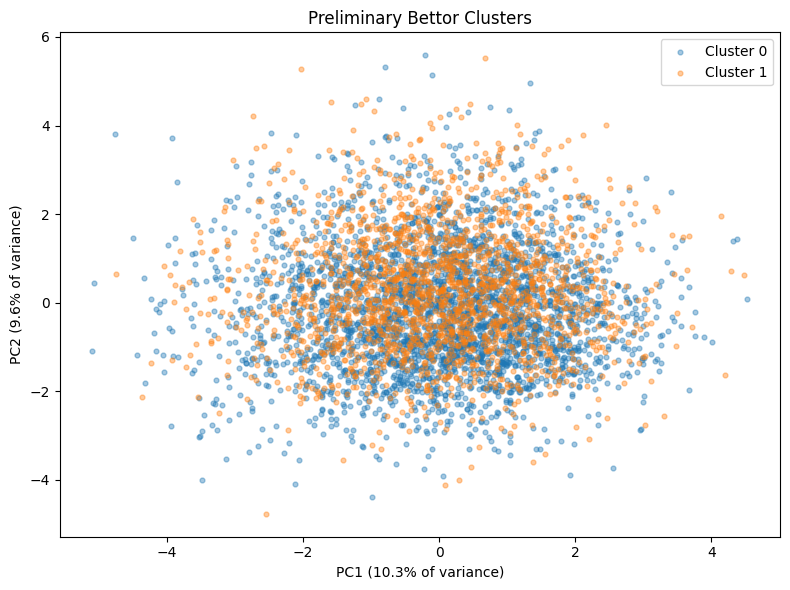

Variance shown in this plot: 19.9%


In [12]:
from sklearn.decomposition import PCA

# Update cluster assignments to the refined seed-42 run
clustered_users["cluster"] = refined_labels[42]

# Refresh the profile summary because assignments may have changed
display(clustered_users["cluster"].value_counts().sort_index())
display(
    clustered_users.groupby("cluster")[profile_columns]
    .mean()
    .round(3)
)

# PCA is for visualization; clustering used all 20 features
pca = PCA(n_components=2, svd_solver="full")
coordinates = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 6))

for cluster in [0, 1]:
    mask = clustered_users["cluster"].to_numpy() == cluster
    ax.scatter(
        coordinates[mask, 0],
        coordinates[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.4,
        s=12
    )

ax.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
ax.set_title("Preliminary Bettor Clusters")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Variance shown in this plot: {explained.sum():.1%}")

## 11. Save Results

In [13]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

user_features.to_csv(output_dir / "user_features.csv")
clustered_users.to_csv(output_dir / "bettor_clusters.csv")

results_df.to_csv(
    output_dir / "initial_kmeans_comparison.csv", index=False
)

refined_stability_df.to_csv(
    output_dir / "refined_cluster_stability.csv", index=False
)

clustered_users.groupby("cluster")[profile_columns].mean().to_csv(
    output_dir / "cluster_profiles.csv"
)

# Save the PCA figure created in the previous cell
fig.savefig(
    output_dir / "pca_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

# Evaluate the refined assignments using the same sampling settings
refined_score = silhouette_score(
    X_scaled,
    clustered_users["cluster"],
    sample_size=2000,
    random_state=42
)

print("Refined silhouette score:", round(refined_score, 4))
print("Results saved in:", output_dir.resolve())

Refined silhouette score: 0.0829
Results saved in: C:\Users\katni\OneDrive\Documents\School\Data Mining\Project\Sports-Betting-Behavioral-Profiling-main\Sports-Betting-Behavioral-Profiling-main\outputs


## Phase 2 Findings

### Data Quality and Exploration
The dataset contains 100,000 simulated bets from 5,000 bettors.
No missing values, duplicate records, duplicate bet IDs, nonpositive
stakes, or odds at or below 1 were found. Stakes and odds were
right-skewed. Football was the most common sport, and single bets
were more common than multiple bets.

### Feature Preparation
We aggregated bets into 23 behavioral features per bettor.
For modeling, we removed redundant or nearly constant features,
replaced stake standard deviation with relative stake variability,
and log-transformed average stake and odds variance. We standardized
the resulting 20 features. Financial outcomes were excluded from
clustering.

### Preliminary Clustering Results
We tested K-means with 2–8 clusters. Two clusters achieved the highest
sampled silhouette score, approximately 0.0829, although there was no
clear elbow. The low score indicates weak separation.

Cluster 0 contains 3,129 bettors with an average stake of 197.09
and average relative stake variability of 0.308.

Cluster 1 contains 1,871 bettors with an average stake of 23.15
and average relative stake variability of 0.522.

The groups have similar odds, sport preferences, bet counts,
and proportions of multiple bets.

### Stability and Limitations
Increasing n_init from 10 to 50 improved agreement across five
random seeds, with pairwise adjusted Rand indices of 0.997–1.000.
This demonstrates consistency across the tested initializations,
but does not establish strong cluster separation.

The first two PCA components explain 19.9% of total variance and
show substantial overlap. Findings are preliminary and apply to
this simulated dataset; they do not demonstrate bettor skill,
motivation, or future profitability.

### Remaining Work
Compare hierarchical clustering with K-means, assess sensitivity
to feature choices and scaling, and compare financial performance
across the behavioral groups.